In [ ]:
!pip install -q timm grad-cam matplotlib seaborn pandas scikit-learn

import torch

print("--- ORTAM KONTROLÜ ---")
print(f"PyTorch Sürümü: {torch.__version__}")
print(f"GPU Kullanılabilir mi?: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Bağlanan GPU: {torch.cuda.get_device_name(0)}")
else:
    print("UYARI: GPU bulunamadı! Runtime ayarlarından GPU'yu seçtiğinden emin ol.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
--- ORTAM KONTROLÜ ---
PyTorch Sürümü: 2.11.0+cu130
GPU Kullanılabilir mi?: True
Bağlanan GPU: Tesla T4


In [ ]:
from google.colab import files
import os
print("Lütfen indirmiş olduğun 'kaggle.json' dosyasını seçip yükle:")
uploaded = files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


print("\nVeri seti indiriliyor...")
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset
!unzip -q brain-tumor-mri-dataset.zip -d ./Brain-Tumor-MRI-Dataset

print("\n VERİ SETİ BAŞARIYLA İNDİRİLDİ VE KLASÖRE ÇIKARILDI!")

Lütfen indirmiş olduğun 'kaggle.json' dosyasını seçip yükle:


Saving kaggle.json to kaggle.json

Veri seti indiriliyor...
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:02<00:00, 70.7MB/s]


 VERİ SETİ BAŞARIYLA İNDİRİLDİ VE KLASÖRE ÇIKARILDI!


--- SINIF BAZLI GÖRÜNTÜ SAYILARI ---
Split       Testing  Training  Toplam
Class                                
glioma          400      1400    1800
meningioma      400      1400    1800
notumor         400      1400    1800
pituitary       400      1400    1800


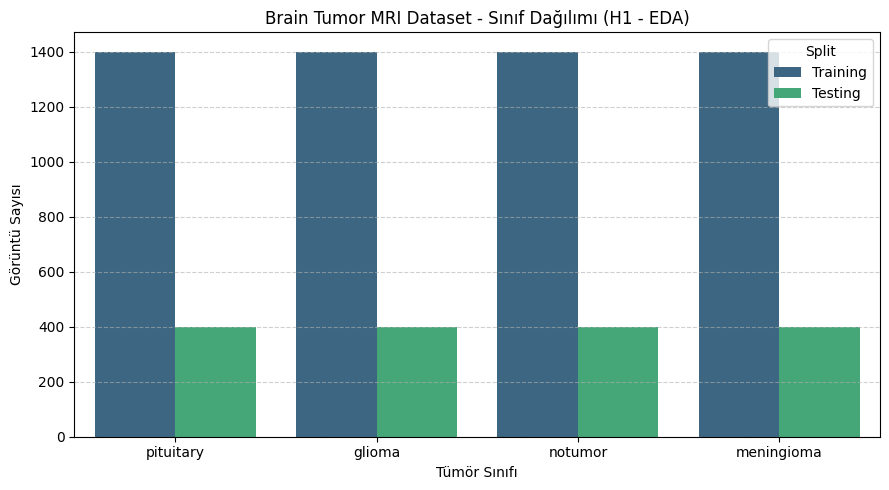

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_dir = "./Brain-Tumor-MRI-Dataset"

counts = {}
for split in ["Training", "Testing"]:
    split_path = os.path.join(data_dir, split)
    if os.path.exists(split_path):
        for class_name in os.listdir(split_path):
            class_path = os.path.join(split_path, class_name)
            if os.path.isdir(class_path):
                num_images = len(os.listdir(class_path))
                counts[(split, class_name)] = num_images


df = pd.DataFrame(list(counts.items()), columns=["Split_Class", "Count"])
df["Split"] = df["Split_Class"].apply(lambda x: x[0])
df["Class"] = df["Split_Class"].apply(lambda x: x[1])
df = df.drop(columns=["Split_Class"])

print("--- SINIF BAZLI GÖRÜNTÜ SAYILARI ---")
pivot_df = df.pivot(index="Class", columns="Split", values="Count")
pivot_df["Toplam"] = pivot_df["Training"] + pivot_df["Testing"]
print(pivot_df)


plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="Class", y="Count", hue="Split", palette="viridis")
plt.title("Brain Tumor MRI Dataset - Sınıf Dağılımı (H1 - EDA)")
plt.xlabel("Tümör Sınıfı")
plt.ylabel("Görüntü Sayısı")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [2]:
from google.colab import drive
import os, shutil, zipfile, json


drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_MRI_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)


kaggle_token = {
    "username": "your_username",
    "key": "your_key"
}

os.makedirs("/root/.kaggle", exist_ok=True)
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_token, f)
os.chmod("/root/.kaggle/kaggle.json", 0o600)


!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p /content/
shutil.copy("/content/brain-tumor-mri-dataset.zip", f"{PROJECT_DIR}/brain-tumor-mri-dataset.zip")


with zipfile.ZipFile("/content/brain-tumor-mri-dataset.zip", 'r') as zip_ref:
    zip_ref.extractall("/content/brain-tumor-mri-dataset")

print("İşlem tamam! Klasörler:", os.listdir("/content/brain-tumor-mri-dataset"))

Mounted at /content/drive
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:01<00:00, 126MB/s]

İşlem tamam! Klasörler: ['Testing', 'Training']
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
brain-tumor-mri-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
İşlem tamam! Klasörler: ['Testing', 'Training']


In [3]:
import os
import glob
import random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = "/content/brain-tumor-mri-dataset"
PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_MRI_Project"

CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
class_to_idx = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}
idx_to_class = {idx: cls_name for idx, cls_name in enumerate(CLASSES)}


data = []
for split_folder in ['Training', 'Testing']:
    for cls_name in CLASSES:
        folder_path = os.path.join(DATA_DIR, split_folder, cls_name)
        for img_path in glob.glob(os.path.join(folder_path, "*.*")):

            rel_path = os.path.relpath(img_path, DATA_DIR)
            data.append({
                "rel_path": rel_path,
                "label_name": cls_name,
                "label": class_to_idx[cls_name]
            })

df = pd.DataFrame(data)
print(f"Toplam Görüntü Sayısı: {len(df)}")


train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df['label'], random_state=SEED
)


val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train Seti: {len(train_df)} (%{len(train_df)/len(df)*100:.1f})")
print(f"Val Seti  : {len(val_df)} (%{len(val_df)/len(df)*100:.1f})")
print(f"Test Seti : {len(test_df)} (%{len(test_df)/len(df)*100:.1f})\n")


os.makedirs("splits", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/splits", exist_ok=True)

for name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    split_df.to_csv(f"splits/{name}.csv", index=False)
    split_df.to_csv(f"{PROJECT_DIR}/splits/{name}.csv", index=False)

print("Sınıf bazlı dağılım kontrolü (Train / Val / Test):")
summary = pd.DataFrame({
    "Train": train_df['label_name'].value_counts(),
    "Val": val_df['label_name'].value_counts(),
    "Test": test_df['label_name'].value_counts()
})
print(summary)
print(f"\nSplit dosyaları kalıcı olarak Drive'a kaydedildi: {PROJECT_DIR}/splits/")

Toplam Görüntü Sayısı: 7200
Train Seti: 5040 (%70.0)
Val Seti  : 1080 (%15.0)
Test Seti : 1080 (%15.0)

Sınıf bazlı dağılım kontrolü (Train / Val / Test):
            Train  Val  Test
label_name                  
glioma       1260  270   270
meningioma   1260  270   270
notumor      1260  270   270
pituitary    1260  270   270

Split dosyaları kalıcı olarak Drive'a kaydedildi: /content/drive/MyDrive/Brain_Tumor_MRI_Project/splits/


In [4]:
IMG_SIZE = 224
BATCH_SIZE = 32

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_test_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.dataframe.loc[idx, "rel_path"])
        label = self.dataframe.loc[idx, "label"]

        image = Image.open(img_path)
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

train_dataset = BrainTumorDataset(train_df, DATA_DIR, transform=train_transforms)
val_dataset = BrainTumorDataset(val_df, DATA_DIR, transform=val_test_transforms)
test_dataset = BrainTumorDataset(test_df, DATA_DIR, transform=val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

sample_imgs, sample_labels = next(iter(train_loader))
print(f"Batch Görüntü Boyutu: {sample_imgs.shape}")
print(f"Batch Etiket Boyutu : {sample_labels.shape}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Batch Görüntü Boyutu: torch.Size([32, 3, 224, 224])
Batch Etiket Boyutu : torch.Size([32])


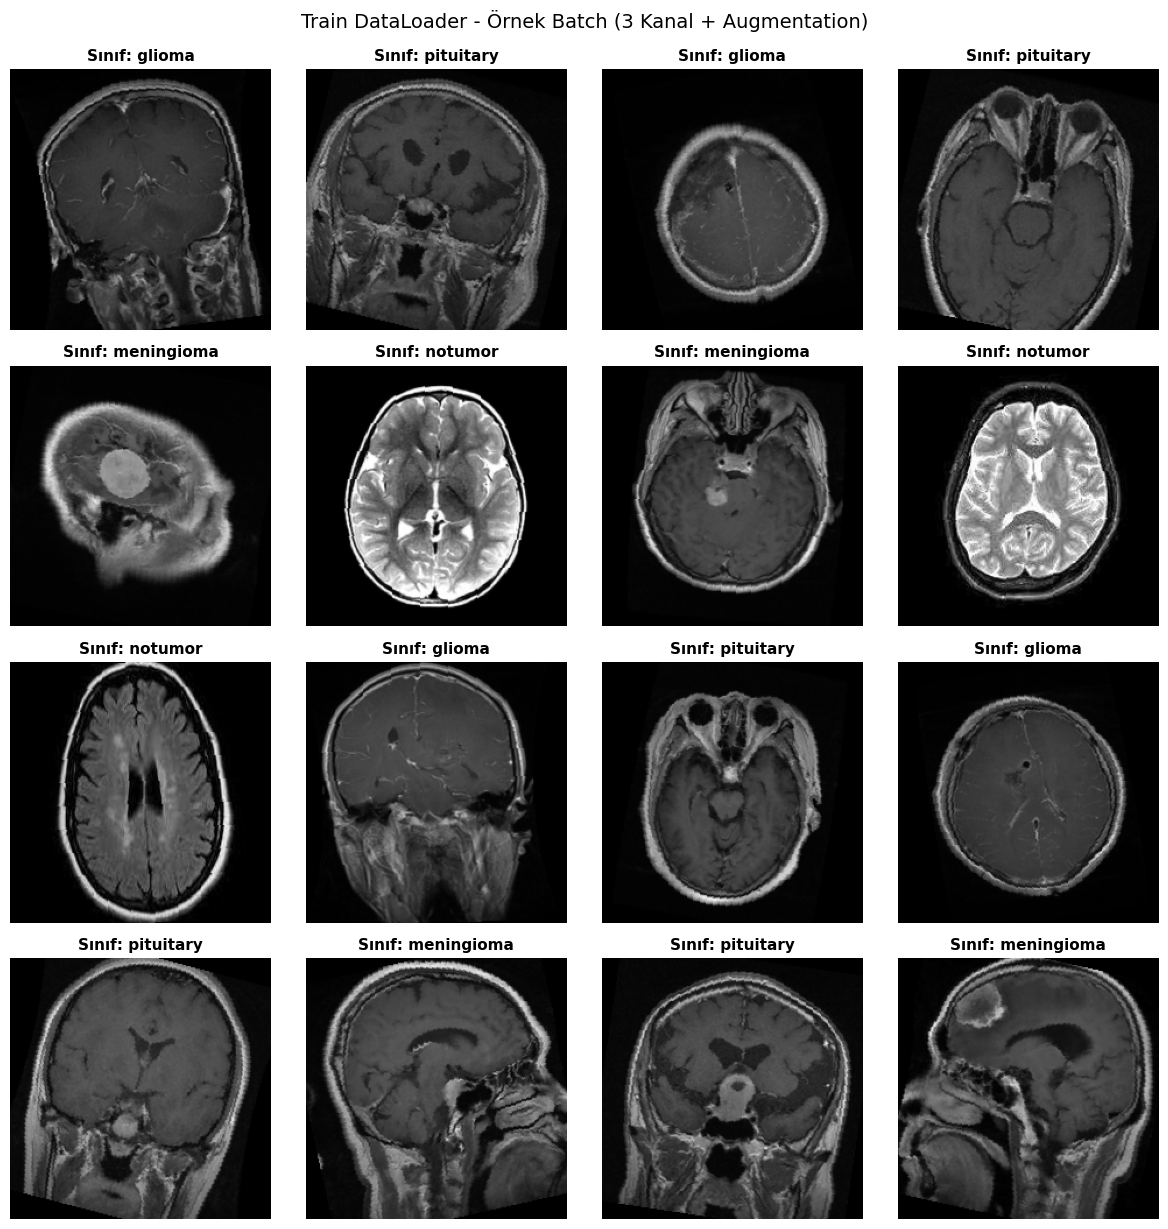

In [5]:
def denormalize(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return torch.clamp(tensor * std + mean, 0, 1)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()

for i in range(16):
    img = denormalize(sample_imgs[i]).permute(1, 2, 0).numpy()
    label_name = idx_to_class[sample_labels[i].item()]

    axes[i].imshow(img)
    axes[i].set_title(f"Sınıf: {label_name}", fontsize=11, fontweight='bold')
    axes[i].axis("off")

plt.tight_layout()
plt.suptitle("Train DataLoader - Örnek Batch (3 Kanal + Augmentation)", fontsize=14, y=1.02)
plt.show()